<a href="https://colab.research.google.com/github/ThomasAlbin/Space-Science-With-Python/blob/main/2026/tisserand_67p_jupiter_encounter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Tisserand Parameter — 67P's Fingerprint Across a Jupiter Encounter

On **4 February 1959**, comet **67P/Churyumov-Gerasimenko** passed within roughly **0.05 AU of Jupiter** — close enough for the giant planet to violently reshape its orbit. According to the numerical-integration study by [Maquet (2015), *A&A*, arXiv:1412.1983](https://arxiv.org/abs/1412.1983), the encounter pulled the comet's perihelion distance in from **more than 2.7 AU to about 1.3 AU**, shrank its semi-major axis from **~4.3 AU to ~3.5 AU**, and pushed its eccentricity up from **~0.37 to ~0.63**. This is *the* reason 67P became an active, observable comet at all — before 1959 it never came much closer to the Sun than the main asteroid belt. Ten years later, in 1969, Klim Churyumov found it on a photographic plate that Svetlana Gerasimenko had taken in Alma-Ata, and in 2014 ESA's **Rosetta** went into orbit around it.

With orbital elements changing that drastically, is there anything about this object that stays the same across the encounter? Yes: the **Tisserand parameter with respect to Jupiter**,

$$ T_J = \frac{a_J}{a} + 2\sqrt{\frac{a}{a_J}\left(1 - e^2\right)}\,\cos i $$

with the comet's semi-major axis $a$, eccentricity $e$ and inclination $i$, and Jupiter's semi-major axis $a_J$. It is an approximate integral of motion for any object making a single close encounter with Jupiter. It is the tool orbital dynamicists actually use to check whether a "new" comet with unfamiliar $a$, $e$, $q$ is secretly the *same body* as a previous apparition that looked completely different on paper. $T_J$ also sorts the small bodies of the Solar System:

* $T_J > 3$: asteroidal orbits
* $2 < T_J < 3$: Jupiter-family comets
* $T_J < 2$: nearly-isotropic (Halley-type and long-period) comets

In this notebook we compute $T_J$ for 67P's orbit **before** and **after** the 1959 encounter and see just how invariant it really is — compared to how much $a$, $e$ and $q$ themselves moved. We need two sources of positions: [**Skyfield**](https://rhodesmill.org/skyfield/) computes where the planets are from JPL's DE440 planetary ephemeris, and JPL's [**Horizons**](https://ssd.jpl.nasa.gov/horizons/) system, queried with `astroquery`, provides the comet's orbit, which JPL integrated numerically through the encounter.

In [1]:
from pathlib import Path
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.time import Time
from astroquery.jplhorizons import Horizons
from skyfield.api import load, load_file
from skyfield.elementslib import osculating_elements_of
from skyfield.framelib import ecliptic_J2000_frame

plt.style.use('dark_background')
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = 11

In [2]:
data_dir = Path("../data")
data_dir.mkdir(exist_ok=True)

# JPL planetary ephemeris DE440 (1849-2150, 32 MB)
ephemeris_files = {
    "de440s.bsp": "https://ssd.jpl.nasa.gov/ftp/eph/planets/bsp/de440s.bsp",
}

for name, url in ephemeris_files.items():
    path = data_dir / name
    if not path.exists():
        print(f"Downloading {name}...")
        urllib.request.urlretrieve(url, path)
    else:
        print(f"{name} already exists.")

ts = load.timescale()
planets = load_file(str(data_dir / "de440s.bsp"))
sun = planets["sun"]
jupiter = planets["jupiter barycenter"]

de440s.bsp already exists.


---
## 1. Jupiter's Orbit Near the Encounter

The Tisserand parameter needs Jupiter's semi-major axis $a_J$ at the time of the encounter. We ask Skyfield for the position and velocity of the **Jupiter barycenter** (Jupiter and its moons) relative to the Sun on the day of the flyby and turn them into **osculating orbital elements** with `osculating_elements_of()`: the Kepler ellipse Jupiter would follow if the Sun and Jupiter were alone. Skyfield works in the equatorial ICRF frame by default; we rotate into the **ecliptic of J2000**, the reference plane of the comet's elements in Section 2. Jupiter's orbit is nearly circular and essentially unaffected by a single comet flyby, so this value stays valid for both the "before" and "after" comparison.

In [3]:
t_flyby = ts.utc(1959, 2, 4)  # closest approach date, Maquet (2015)

jupiter_state = (jupiter - sun).at(t_flyby)  # heliocentric position and velocity
jupiter_elements = osculating_elements_of(jupiter_state, ecliptic_J2000_frame.rotation_at(t_flyby))

a_jup_au = jupiter_elements.semi_major_axis.au

print(f"Jupiter semi-major axis a_J: {a_jup_au:.4f} AU")
print(f"Jupiter eccentricity:        {jupiter_elements.eccentricity:.4f}")
print(f"Jupiter inclination:         {jupiter_elements.inclination.degrees:.4f} deg")
print(f"Jupiter's distance from the Sun on 4 Feb 1959: {jupiter_state.distance().au:.4f} AU")

Jupiter semi-major axis a_J: 5.2025 AU
Jupiter eccentricity:        0.0488
Jupiter inclination:         1.3050 deg
Jupiter's distance from the Sun on 4 Feb 1959: 5.4045 AU


For the gravitational parameter, Skyfield uses the sum of the Sun's and Jupiter's $GM$, as the two-body problem requires. Note that Jupiter's orbit is not a perfect circle: on the day of the encounter it was 5.40 AU from the Sun, not 5.20 AU. We will come back to this in the conclusion.

---
## 2. 67P's Orbit Before and After the 1959 Encounter

Horizons computes the comet's motion through the encounter, including the gravity of the Sun and the planets. We ask it for 67P's osculating elements relative to the centre of the Sun (`500@10`) in the ecliptic frame at three dates:

* **1 January 1955** and **1 January 1965**, four and six years away from the encounter, when Jupiter was far from the comet
* **13 August 2015**, 67P's perihelion with Rosetta in orbit around it, as a cross-check against the precise elements from the IMCCE comet database quoted in Maquet (2015) Table 1 ($a = 3.4619$ AU, $e = 0.6409$, $q = 1.2433$ AU)

Horizons holds several orbit solutions for 67P; `closest_apparition=True` selects JPL's most recent one.

In [4]:
epochs = Time(["1955-01-01", "1965-01-01", "2015-08-13"], scale="tdb")

query = Horizons(id="67P", id_type="designation", location="500@10", epochs=list(epochs.jd))
elements_67p = query.elements(refplane="ecliptic", closest_apparition=True).to_pandas()

rows = {"a": "Semi-major axis a (AU)", "e": "Eccentricity e", "q": "Perihelion distance q (AU)",
        "incl": "Inclination i (deg)"}
elements = elements_67p[list(rows)].rename(columns=rows).T
elements.columns = ["Before 1959 (1955)", "After 1959 (1965)", "Rosetta (2015)"]
elements.round(4)

,Before 1959 (1955),After 1959 (1965),Rosetta (2015)
Semi-major axis a (AU),4.3163,3.4982,3.4619
Eccentricity e,0.3648,0.6340,0.6409
Perihelion distance q (AU),2.7416,1.2802,1.2433
Inclination i (deg),23.1843,7.1599,7.0403


The 1955 and 1965 values agree with Maquet (2015): $a$ dropped from 4.3 to 3.5 AU, $q$ from 2.7 to 1.3 AU, and $e$ rose from 0.37 to 0.63. The 2015 orbit matches the IMCCE elements to four decimal places. But the table shows one more change: the encounter also tilted the orbital plane, and the inclination dropped from **23°** to **7°**.

---
## 3. The Tisserand Parameter Before and After

We now evaluate $T_J$ for each set of elements using Jupiter's $a_J$ from Section 1.

In [5]:
def tisserand(a_au, e, i_deg, a_jupiter_au):
    i_rad = np.radians(i_deg)
    return a_jupiter_au / a_au + 2.0 * np.sqrt((a_au / a_jupiter_au) * (1.0 - e ** 2)) * np.cos(i_rad)

before, after, rosetta = (elements_67p.iloc[k] for k in range(3))

T_before = tisserand(before["a"], before["e"], before["incl"], a_jup_au)
T_after  = tisserand(after["a"], after["e"], after["incl"], a_jup_au)
T_rosetta = tisserand(rosetta["a"], rosetta["e"], rosetta["incl"], a_jup_au)

print(f"T_J before the 1959 encounter: {T_before:.4f}")
print(f"T_J after the 1959 encounter:  {T_after:.4f}")
print(f"T_J in 2015 (Rosetta):         {T_rosetta:.4f}   (cross-check against 'after')")

print(f"\nChange in T_J:  {T_after - T_before:+.4f}  ({100 * (T_after - T_before) / T_before:+.2f}%)")
for column, name in [("a", "a"), ("e", "e"), ("q", "q"), ("incl", "i")]:
    print(f"Change in {name}:     {100 * (after[column] - before[column]) / before[column]:+.2f}%")

T_J before the 1959 encounter: 2.7645
T_J after the 1959 encounter:  2.7456
T_J in 2015 (Rosetta):         2.7457   (cross-check against 'after')

Change in T_J:  -0.0189  (-0.69%)
Change in a:     -18.95%
Change in e:     +73.79%
Change in q:     -53.30%
Change in i:     -69.12%


$a$, $e$, $q$ and $i$ each moved by tens of percent — the orbit is, in every visible sense, a different orbit after 1959. Yet $T_J$ changed by less than 1 %, and both values sit comfortably inside the **Jupiter-family comet** band ($2 < T_J < 3$). The 2015 value also matches JPL's [Small-Body Database](https://ssd.jpl.nasa.gov/tools/sbdb_lookup.html#/?sstr=67P), which lists $T_J = 2.746$ for 67P.

The drop in inclination is part of this balance. Let's see what happens if we pretend that only the size and shape of the orbit changed and use the 1965 inclination for 1955 as well:

In [6]:
T_before_same_i = tisserand(before["a"], before["e"], after["incl"], a_jup_au)

print(f"T_J before, with the inclination of 1965: {T_before_same_i:.4f}")
print(f"Change in T_J:  {T_after - T_before_same_i:+.4f}  ({100 * (T_after - T_before_same_i) / T_before_same_i:+.2f}%)")

T_J before, with the inclination of 1965: 2.8882
Change in T_J:  -0.1427  (-4.94%)


The change would be about seven times larger. Jupiter's pull changes $a$, $e$ and $i$ *together*. The first term, $a_J/a$, grows by 0.28 as the orbit shrinks. The second term shrinks by 0.30, because the smaller $a$ and the larger $e$ reduce the square root — but the drop in inclination raises $\cos i$ from 0.92 to 0.99 and keeps the second term from shrinking even more. Only all three elements combined keep $T_J$ (almost) constant.

That's the point of the Tisserand parameter: it is (approximately) conserved *through* the encounter that changed everything else, which is exactly what lets astronomers confirm that a comet re-discovered with wildly different orbital elements is still the same object it was decades or centuries earlier.

---
## 4. Visualising the Two Orbits

Finally we look at the real trajectory. We ask Horizons for 67P's position relative to the Sun for every day from 1950 to September 1965: roughly one revolution on the old orbit (period ~9 years) and one on the new orbit (~6.5 years). Skyfield gives us the positions of Jupiter, Mars and the Earth at the same times, rotated into the same ecliptic frame. The distance between 67P and Jupiter also lets us check the date and distance of the encounter ourselves.

In [7]:
span = {"start": "1950-01-01", "stop": "1965-09-01", "step": "1d"}
query = Horizons(id="67P", id_type="designation", location="500@10", epochs=span)
vectors = query.vectors(refplane="ecliptic", closest_apparition=True).to_pandas()

t = ts.tdb_jd(vectors["datetime_jd"].to_numpy())
pos_67p = vectors[["x", "y", "z"]].to_numpy()  # AU

def heliocentric_positions(body):
    return (body - sun).at(t).frame_xyz(ecliptic_J2000_frame).au.T  # AU

pos_jup = heliocentric_positions(jupiter)
pos_mars = heliocentric_positions(planets["mars barycenter"])
pos_earth = heliocentric_positions(planets["earth barycenter"])

distance_jup = np.linalg.norm(pos_67p - pos_jup, axis=1)
k_flyby = distance_jup.argmin()

print(f"Closest approach to Jupiter: {t[k_flyby].tdb_strftime('%Y-%m-%d')}, "
      f"{distance_jup[k_flyby]:.4f} AU ({distance_jup[k_flyby] * 149.6:.1f} million km)")  # 1 AU = 149.6 million km

Closest approach to Jupiter: 1959-02-04, 0.0515 AU (7.7 million km)


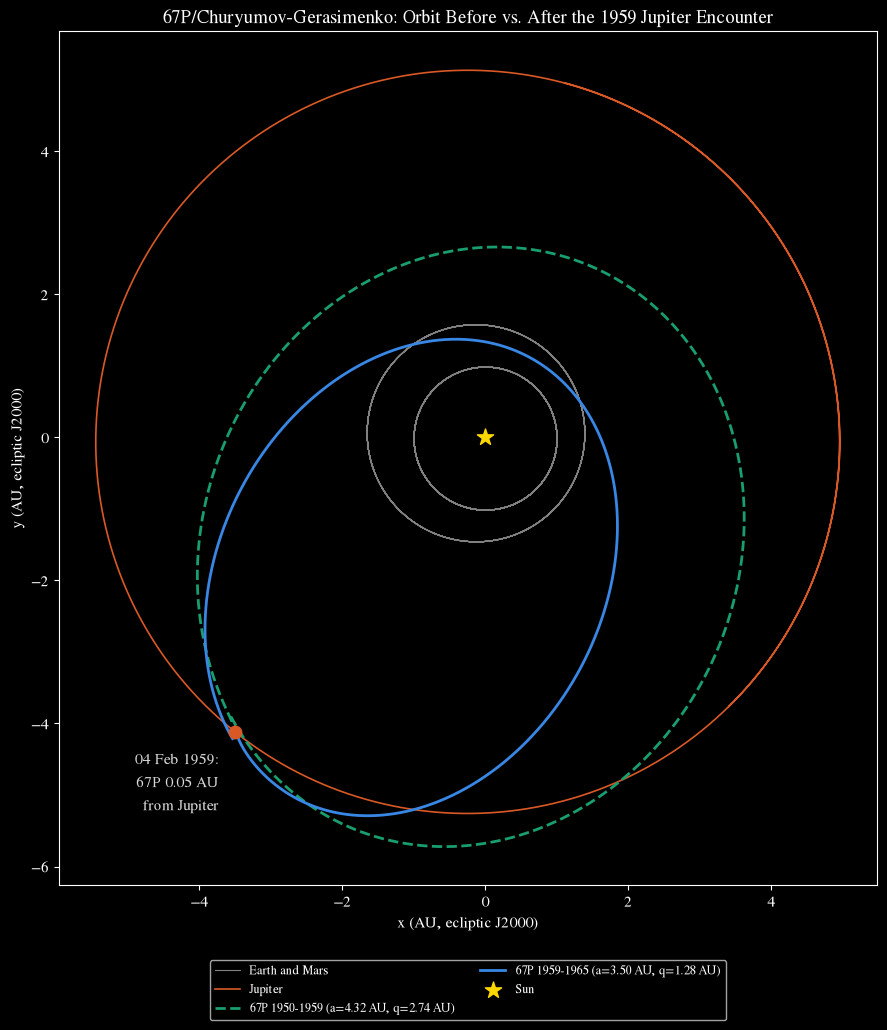

In [8]:
pos_before, pos_after = pos_67p[:k_flyby + 1], pos_67p[k_flyby:]

comet_before_color, comet_after_color, jupiter_color = '#199e70', '#3987e5', '#d95926'

fig, ax = plt.subplots(figsize=(9, 10))

ax.plot(pos_earth[:, 0], pos_earth[:, 1], color='0.5', lw=0.8, label='Earth and Mars')
ax.plot(pos_mars[:, 0], pos_mars[:, 1], color='0.5', lw=0.8)
ax.plot(pos_jup[:, 0], pos_jup[:, 1], color=jupiter_color, lw=1.2, label='Jupiter')

ax.plot(pos_before[:, 0], pos_before[:, 1], color=comet_before_color, lw=2, ls='--',
        label=f'67P 1950-1959 (a={before["a"]:.2f} AU, q={before["q"]:.2f} AU)')
ax.plot(pos_after[:, 0], pos_after[:, 1], color=comet_after_color, lw=2,
        label=f'67P 1959-1965 (a={after["a"]:.2f} AU, q={after["q"]:.2f} AU)')

ax.scatter(0, 0, color='gold', s=150, marker='*', zorder=6, label='Sun')
ax.scatter(*pos_jup[k_flyby, :2], color=jupiter_color, s=80, zorder=6)
ax.annotate(f"{t[k_flyby].tdb_strftime('%d %b %Y')}:\n67P {distance_jup[k_flyby]:.2f} AU\nfrom Jupiter", pos_jup[k_flyby, :2],
            xytext=(-12, -12), textcoords='offset points', ha='right', va='top', color='0.85')

ax.set_xlabel('x (AU, ecliptic J2000)')
ax.set_ylabel('y (AU, ecliptic J2000)')
ax.set_aspect('equal')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9)
ax.set_title('67P/Churyumov-Gerasimenko: Orbit Before vs. After the 1959 Jupiter Encounter')
plt.tight_layout()
plt.show()

Before 1959 (dashed), 67P's perihelion lay far outside the orbit of Mars, in the asteroid belt. After the encounter, it comes inside the orbit of Mars, 1.28 AU from the Sun, where the Sun's heat makes it active. Both orbits meet at the point where 67P met Jupiter.

---
## 5. Conclusion

The 1959 encounter with Jupiter did more to reshape 67P's orbit than anything else in its recent history: the semi-major axis shrank by about 19 %, the eccentricity jumped by more than 70 %, the perihelion distance was cut in half and the inclination fell from 23° to 7° — which is precisely what dragged the comet closer to the Sun to become more active and, decades later, observable and reachable by Rosetta. And yet the Tisserand parameter, the one quantity built specifically to survive a Jupiter encounter, drifted by less than 1 % and never left the Jupiter-family-comet band.

Why only *almost* conserved? $T_J$ is derived for the restricted three-body problem: the Sun, a Jupiter on a circular orbit and a massless comet. The real Jupiter was 5.40 AU from the Sun in 1959 instead of 5.20 AU, and Saturn and the other planets pull on the comet as well. That leaves the small residual.

That contrast **is** the point: $T_J$ isn't just a classification label, it's a dynamical fingerprint that identifies 67P as the same body before and after an encounter that changed everything else about its orbit.